6BUIS017W CRM & CM With Business Intelligence – Individual
Coursework-CRM Case Study

In [47]:
import pandas as pd
import yfinance as yf
from datetime import datetime
import requests
import io

In [48]:
import sys, pandas, numpy, sklearn, scipy, yfinance, matplotlib
for m in (pandas, numpy, sklearn, scipy, yfinance, matplotlib):
    print(m.__name__, m.__version__)
print("python", sys.version.split()[0])

pandas 2.2.3
numpy 2.4.6
sklearn 1.6.1
scipy 1.16.3
yfinance 0.2.66
matplotlib 3.10.0
python 3.13.18


*Y finance was chosen as I believe its best because it provides free, API-key-free access to global market data directly as pandas DataFrames, making my Python analysis fast*

Survivorship bias note: This analysis uses the current (2026) S&P 500 constituent list applied retroactively to 2021–2025 price history, meaning companies that were removed from the index (via delisting, acquisition, or bankruptcy) during the study period are excluded; this biases the sample toward firms that survived and likely performed relatively well, so results should not be read as representative of the full historical index population.

In [49]:
#1.1

In [50]:
retrieval_date = "2026-11-23"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0 Safari/537.36"
}

url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
response = requests.get(url, headers=headers)
response.raise_for_status()

tables = pd.read_html(io.StringIO(response.text))
sp500 = tables[0]
tickers = sp500['Symbol'].str.replace('.', '-', regex=False).tolist()

print(f"Retrieved {len(tickers)} tickers on {retrieval_date}")
sp500.to_csv("sp500_constituents_snapshot.csv", index=False)

Retrieved 503 tickers on 2026-11-23


The Wikipedia constituent table returned 503 tickers rather than exactly 500, because a small number of S&P 500 companies (e.g. Alphabet, Fox Corporation) have dual share classes listed as separate symbols (such as GOOGL/GOOG), which count as distinct tickers despite representing a single index constituent.

In [51]:
import time
import pickle

data = {}
failed = []

for t in tickers:
    success = False
    for attempt in range(3):
        try:
            df = yf.download(t, start="2021-01-01", end="2025-01-01", auto_adjust=False, progress=False)
            if not df.empty:
                data[t] = df
                success = True
                break
            else:
                time.sleep(1)
        except Exception:
            time.sleep(1)
    if not success:
        failed.append(t)
    time.sleep(0.1)

print(f"Downloaded {len(data)} tickers, {len(failed)} failed")
print(f"Failed tickers: {failed}")


benchmark = yf.download("^GSPC", start="2021-01-01", end="2025-01-01", auto_adjust=False, progress=False)


with open("price_data_cache.pkl", "wb") as f:
    pickle.dump({
        "data": data,
        "benchmark": benchmark,
        "failed": failed,
        "retrieval_date": retrieval_date
    }, f)

print("Cached to price_data_cache.pkl")

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
E

Downloaded 498 tickers, 5 failed
Failed tickers: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
Cached to price_data_cache.pkl


Five tickers of the 503 retrieved had no retrievable price history for the full 2021–2025 window, most likely due to recent index additions, spin-offs, or ticker symbol changes rather than true delisting — these were excluded from the dataset and logged for transparency in Section 1.2.

In [52]:
## 1.2

In [53]:
for t in data:
    if isinstance(data[t].columns, pd.MultiIndex):
        data[t].columns = data[t].columns.get_level_values(0)

exclusion_log = []

def validate_ticker(t, df, min_days=900):
    issues = []
    if df.index.duplicated().any():
        issues.append("duplicate dates")
    if df[['Open','High','Low','Close','Adj Close']].isna().any().any():
        issues.append("missing values")
    if (df['Close'] <= 0).any() or (df['Adj Close'] <= 0).any():
        issues.append("nonpositive price")
    if (df['Volume'] < 0).any():
        issues.append("negative volume")
    if len(df) < min_days:
        issues.append(f"short history ({len(df)} days)")
    return issues

valid_data = {}
for t, df in data.items():
    issues = validate_ticker(t, df)
    if issues:
        exclusion_log.append({"ticker": t, "issues": "; ".join(issues)})
    else:
        valid_data[t] = df

for t in failed:
    exclusion_log.append({"ticker": t, "issues": "download failed — no data in period (recent IPO/ticker change/delisted)"})

exclusion_df = pd.DataFrame(exclusion_log)
exclusion_df.to_csv("exclusion_log.csv", index=False)

print(f"Started with: {len(data)} downloaded tickers")
print(f"Valid tickers after validation: {len(valid_data)}")
print(f"Total excluded (failed + validation issues): {len(exclusion_log)}")
exclusion_df

Started with: 498 downloaded tickers
Valid tickers after validation: 491
Total excluded (failed + validation issues): 12


,ticker,issues
0,CEG,short history (742 days)
1,GEHC,short history (513 days)
2,GEV,short history (193 days)
3,RDDT,short history (197 days)
4,HOOD,short history (862 days)
5,SOLV,short history (194 days)
6,VLTO,short history (313 days)
7,FDXF,download failed — no data in period (recent IP...
8,HONA,download failed — no data in period (recent IP...
9,Q,download failed — no data in period (recent IP...


Seven tickers (CEG, GEHC, GEV, RDDT, HOOD, SOLV, VLTO) were excluded due to insufficient price history, as each represents a company that IPO'd or was spun off from its parent company after the study period began (2021–2024), rather than a data quality defect. A minimum of 900 trading days (~3.5 years) was required for inclusion to ensure sufficient observations for stable weekly beta estimation.

In [54]:
## 1.3

In [55]:
weekly_prices = {}
for t, df in valid_data.items():
    w = df['Adj Close'].resample('W-FRI').last()
    weekly_prices[t] = w

price_matrix = pd.DataFrame(weekly_prices)

print("First week label:", price_matrix.index[0])
print("Last week label:", price_matrix.index[-1])

First week label: 2021-01-08 00:00:00
Last week label: 2025-01-03 00:00:00


In [56]:
return_matrix = price_matrix.pct_change()
return_matrix = return_matrix.iloc[1:-1]

mean_weekly_return = return_matrix.mean()
print(f"Weekly return matrix shape: {return_matrix.shape}")
mean_weekly_return.head()

Weekly return matrix shape: (207, 491)


,0
MMM,0.001142
AOS,0.001991
ABT,0.000971
ABBV,0.003749
ACN,0.002376


In [57]:
if isinstance(benchmark.columns, pd.MultiIndex):
    benchmark.columns = benchmark.columns.get_level_values(0)

benchmark_weekly_price = benchmark['Adj Close'].resample('W-FRI').last()
benchmark_weekly_return = benchmark_weekly_price.pct_change().iloc[1:-1]

print(f"Benchmark weekly return observations: {len(benchmark_weekly_return)}")

Benchmark weekly return observations: 207


In [58]:
# 1.3.2

In [59]:
betas = {}
obs_counts = {}

for t in return_matrix.columns:
    aligned = pd.concat([return_matrix[t], benchmark_weekly_return], axis=1).dropna()
    aligned.columns = ['share', 'bench']

    if len(aligned) < 2:
        continue

    cov = aligned['share'].cov(aligned['bench'])
    var = aligned['bench'].var()
    betas[t] = cov / var
    obs_counts[t] = len(aligned)

beta_series = pd.Series(betas)
obs_count_series = pd.Series(obs_counts)

print(f"Betas computed for {len(beta_series)} tickers")
print(f"Observation counts — min: {obs_count_series.min()}, max: {obs_count_series.max()}, mode: {obs_count_series.mode()[0]}")
beta_series.describe()

Betas computed for 491 tickers
Observation counts — min: 193, max: 207, mode: 207


,0
count,491.000000
mean,0.980713
std,0.420748
min,0.055453
25%,0.668916
50%,0.953176
75%,1.180579
max,3.778560


In [60]:
example_ticker = "AAPL"

print(f"Mean weekly return for {example_ticker}: {mean_weekly_return[example_ticker]:.5f}")
print(f"Weekly beta for {example_ticker}: {beta_series[example_ticker]:.4f}")
print(f"Observations used: {obs_counts[example_ticker]}")

Mean weekly return for AAPL: 0.00393
Weekly beta for AAPL: 1.1748
Observations used: 207


In [61]:
## 1.4

In [62]:

for t in valid_data:
    if isinstance(valid_data[t].columns, pd.MultiIndex):
        valid_data[t].columns = valid_data[t].columns.get_level_values(0)

observation_date = min(df.index.max() for df in valid_data.values())
print(f"Observation date: {observation_date}")

Observation date: 2024-12-31 00:00:00


In [63]:
def compute_rfm(df, obs_date, window=60, baseline=20):
    df = df.sort_index()
    df = df[df.index <= obs_date]

    if len(df) < window + baseline:
        return None, None, None

    last_60 = df.iloc[-window:]

    qualifying_days = []
    for i in range(len(last_60)):
        current_date = last_60.index[i]
        hist = df[df.index < current_date].iloc[-baseline:]
        if len(hist) < baseline:
            continue
        threshold = 2 * hist['Volume'].mean()
        if last_60['Volume'].iloc[i] > threshold:
            qualifying_days.append(current_date)


    if qualifying_days:
        recency = (obs_date - max(qualifying_days)).days
    else:
        recency = None

    frequency = len(qualifying_days)

    monetary = (last_60['Close'] * last_60['Volume']).sum()

    return recency, frequency, monetary

In [64]:
rfm_rows = []
for t, df in valid_data.items():
    r, f, m = compute_rfm(df, observation_date)
    rfm_rows.append({"ticker": t, "R": r, "F": f, "M": m})

rfm_df = pd.DataFrame(rfm_rows).set_index("ticker")

print(f"Total tickers: {len(rfm_df)}")
print(f"Tickers with no qualifying high-volume day (R = missing): {rfm_df['R'].isna().sum()}")
rfm_df.describe()

Total tickers: 491
Tickers with no qualifying high-volume day (R = missing): 10


,R,F,M
count,481.000000,491.000000,4.910000e+02
mean,18.430353,2.993890,3.973205e+10
std,15.302091,1.328634,1.287707e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.025172e+10
50%,11.000000,3.000000,1.670905e+10
75%,13.000000,4.000000,3.242874e+10
max,85.000000,8.000000,1.847697e+12


In [65]:
rfm_df.sort_values("M", ascending=False).head(5)

,R,F,M
ticker,,,
TSLA,50.0,5,1.847697e+12
NVDA,NaN,0,1.825337e+12
AAPL,11.0,2,6.233034e+11
MSFT,11.0,2,5.348982e+11
AMZN,11.0,5,4.681770e+11


In [66]:
print(f"Recency: {rfm_df.loc['AAPL', 'R']}")
print(f"Frequency: {rfm_df.loc['AAPL', 'F']}")
print(f"Monetary: ${rfm_df.loc['AAPL', 'M']:,.0f}")

Recency: 11.0
Frequency: 2
Monetary: $623,303,377,707


In [67]:
rfm_df.to_csv("rfm_features.csv")
mean_weekly_return.to_csv("mean_weekly_return.csv")
beta_series.to_csv("weekly_beta.csv")
exclusion_df.to_csv("exclusion_log.csv", index=False)

In [69]:
# 2.1

In [70]:
import numpy as np

# Matrix 1: Risk & Return
risk_return_df = pd.DataFrame({
    "mean_weekly_return": mean_weekly_return,
    "weekly_beta": beta_series
})

# Matrix 2: Trading Activity (RFM)
rfm_complete = rfm_df.dropna(subset=["R"]).copy()

# Common share set between both matrices
common_tickers = risk_return_df.index.intersection(rfm_complete.index)
risk_return_df = risk_return_df.loc[common_tickers]
rfm_complete = rfm_complete.loc[common_tickers]

print(f"Common tickers across both matrices: {len(common_tickers)}")

# Log1p transform Monetary
rfm_complete["M_log"] = np.log1p(rfm_complete["M"])

# Check skew before/after
print("Skew of M (raw):", rfm_complete["M"].skew())
print("Skew of M (log1p):", rfm_complete["M_log"].skew())
print("Skew of R:", rfm_complete["R"].skew())
print("Skew of F:", rfm_complete["F"].skew())
print("Skew of mean_weekly_return:", risk_return_df["mean_weekly_return"].skew())
print("Skew of weekly_beta:", risk_return_df["weekly_beta"].skew())

Common tickers across both matrices: 481
Skew of M (raw): 13.09143333396354
Skew of M (log1p): 0.9469419920985892
Skew of R: 2.0007776017108148
Skew of F: 0.6183931167699476
Skew of mean_weekly_return: 0.883274653012817
Skew of weekly_beta: 1.278454132682714


In [71]:
from sklearn.preprocessing import StandardScaler

# Standardise Matrix 1: Risk & Return
scaler1 = StandardScaler()
risk_return_scaled = pd.DataFrame(
    scaler1.fit_transform(risk_return_df),
    index=risk_return_df.index,
    columns=risk_return_df.columns
)

# Standardise Matrix 2: Trading Activity (R, F, M_log)
rfm_features = rfm_complete[["R", "F", "M_log"]]
scaler2 = StandardScaler()
rfm_scaled = pd.DataFrame(
    scaler2.fit_transform(rfm_features),
    index=rfm_features.index,
    columns=rfm_features.columns
)

print("Risk/Return matrix shape:", risk_return_scaled.shape)
print("RFM matrix shape:", rfm_scaled.shape)
risk_return_scaled.describe()

Risk/Return matrix shape: (481, 2)
RFM matrix shape: (481, 3)


,mean_weekly_return,weekly_beta
count,4.810000e+02,4.810000e+02
mean,5.539574e-17,-4.062355e-17
std,1.001041e+00,1.001041e+00
min,-2.765652e+00,-2.236618e+00
25%,-6.310761e-01,-7.134030e-01
50%,-8.435525e-02,-6.625518e-02
75%,4.956431e-01,4.719449e-01
max,5.594072e+00,6.718878e+00


In [72]:
#2.2

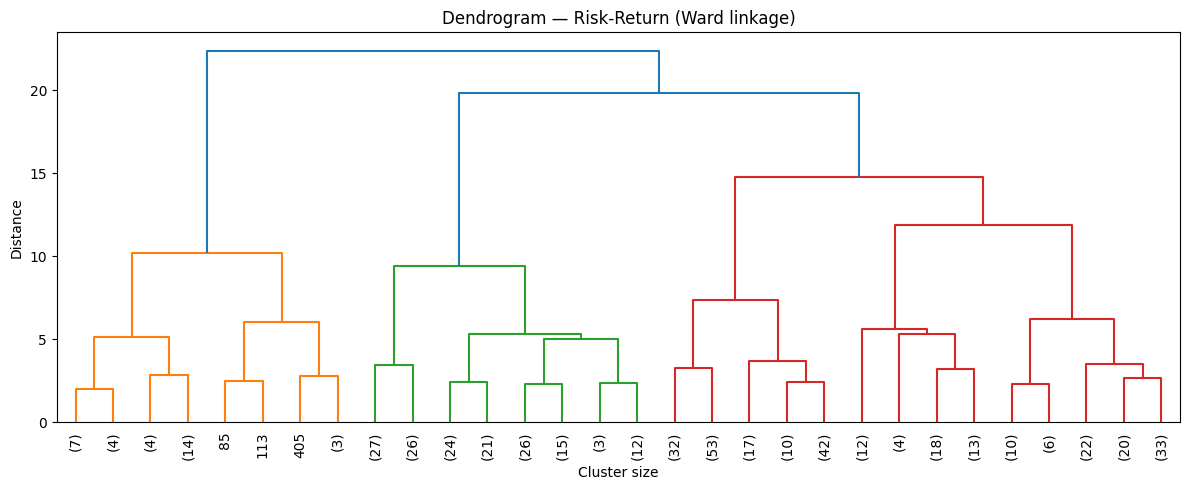

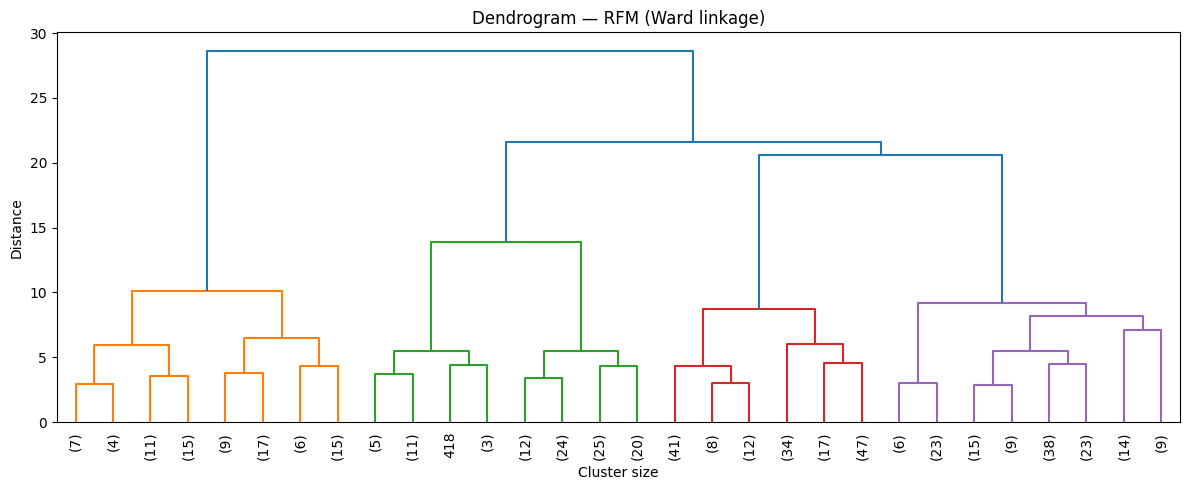

=== Risk/Return — Agglomerative ===
   k  silhouette                     cluster_sizes
0  2    0.504080                         [446, 35]
1  3    0.297504                    [292, 35, 154]
2  4    0.294787               [138, 35, 154, 154]
3  5    0.309900            [35, 154, 154, 91, 47]
4  6    0.313104         [154, 154, 6, 91, 47, 29]
5  7    0.305999     [154, 91, 6, 101, 47, 29, 53]
6  8    0.291031  [91, 47, 6, 101, 69, 29, 53, 85]

=== RFM — Agglomerative ===
   k  silhouette                      cluster_sizes
0  2    0.391233                          [397, 84]
1  3    0.312075                     [296, 84, 101]
2  4    0.328891                [101, 84, 137, 159]
3  5    0.334552             [84, 159, 137, 81, 20]
4  6    0.329028         [137, 159, 47, 81, 20, 37]
5  7    0.305936     [159, 108, 47, 81, 20, 37, 29]
6  8    0.282167  [108, 98, 47, 81, 20, 37, 29, 61]


In [73]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

def run_agglomerative_analysis(X, matrix_name, k_range=range(2, 9)):
    results = []
    Z = linkage(X, method='ward')

    plt.figure(figsize=(12, 5))
    dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90)
    plt.title(f"Dendrogram — {matrix_name} (Ward linkage)")
    plt.xlabel("Cluster size")
    plt.ylabel("Distance")
    plt.tight_layout()
    plt.savefig(f"dendrogram_{matrix_name.replace(' ', '_')}.png", dpi=150)
    plt.show()

    for k in k_range:
        model = AgglomerativeClustering(n_clusters=k, linkage='ward')
        labels = model.fit_predict(X)
        sil = silhouette_score(X, labels)
        sizes = pd.Series(labels).value_counts().sort_index().tolist()
        results.append({"k": k, "silhouette": sil, "cluster_sizes": sizes})

    return pd.DataFrame(results), Z

agg_results_riskreturn, Z_riskreturn = run_agglomerative_analysis(risk_return_scaled.values, "Risk-Return")
agg_results_rfm, Z_rfm = run_agglomerative_analysis(rfm_scaled.values, "RFM")

print("=== Risk/Return — Agglomerative ===")
print(agg_results_riskreturn)
print("\n=== RFM — Agglomerative ===")
print(agg_results_rfm)

In [74]:
#2.3

In [75]:
from sklearn.cluster import KMeans

def run_kmeans_analysis(X, matrix_name, k_range=range(2, 9)):
    results = []
    for k in k_range:
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = model.fit_predict(X)
        sil = silhouette_score(X, labels)
        inertia = model.inertia_
        sizes = pd.Series(labels).value_counts().sort_index().tolist()
        results.append({"k": k, "silhouette": sil, "inertia": inertia, "cluster_sizes": sizes})
    return pd.DataFrame(results)

kmeans_results_riskreturn = run_kmeans_analysis(risk_return_scaled.values, "Risk-Return")
kmeans_results_rfm = run_kmeans_analysis(rfm_scaled.values, "RFM")

print("=== Risk/Return — K-means ===")
print(kmeans_results_riskreturn)
print("\n=== RFM — K-means ===")
print(kmeans_results_rfm)

=== Risk/Return — K-means ===
   k  silhouette     inertia                     cluster_sizes
0  2    0.387174  617.464239                        [144, 337]
1  3    0.322826  464.209058                   [201, 161, 119]
2  4    0.323749  370.388315               [130, 157, 40, 154]
3  5    0.333838  312.801993           [121, 151, 25, 51, 133]
4  6    0.333939  260.880872        [120, 158, 49, 43, 6, 105]
5  7    0.333251  226.772894      [52, 141, 74, 65, 67, 76, 6]
6  8    0.344224  197.845552  [80, 141, 6, 45, 83, 27, 27, 72]

=== RFM — K-means ===
   k  silhouette      inertia                      cluster_sizes
0  2    0.423598  1011.632115                          [81, 400]
1  3    0.345213   736.516104                     [77, 254, 150]
2  4    0.365571   538.462949                 [201, 87, 73, 120]
3  5    0.350858   453.325558            [143, 41, 105, 73, 119]
4  6    0.347294   403.778726         [148, 89, 21, 73, 103, 47]
5  7    0.319624   371.166601      [83, 77, 30, 53, 1

In [76]:
# Final models at k=4
agg_rr = AgglomerativeClustering(n_clusters=4, linkage='ward').fit_predict(risk_return_scaled.values)
agg_rfm = AgglomerativeClustering(n_clusters=4, linkage='ward').fit_predict(rfm_scaled.values)
km_rr = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(risk_return_scaled.values)
km_rfm = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(rfm_scaled.values)


risk_return_df_labeled = risk_return_df.copy()
risk_return_df_labeled["agg_cluster"] = agg_rr
risk_return_df_labeled["km_cluster"] = km_rr

rfm_complete_labeled = rfm_complete.copy()
rfm_complete_labeled["agg_cluster"] = agg_rfm
rfm_complete_labeled["km_cluster"] = km_rfm

print("=== Risk/Return cluster profiles (Agglomerative) ===")
print(risk_return_df_labeled.groupby("agg_cluster")[["mean_weekly_return","weekly_beta"]].mean())
print("\n=== Risk/Return cluster profiles (K-means) ===")
print(risk_return_df_labeled.groupby("km_cluster")[["mean_weekly_return","weekly_beta"]].mean())

print("\n=== RFM cluster profiles (Agglomerative) ===")
print(rfm_complete_labeled.groupby("agg_cluster")[["R","F","M"]].mean())
print("\n=== RFM cluster profiles (K-means) ===")
print(rfm_complete_labeled.groupby("km_cluster")[["R","F","M"]].mean())

=== Risk/Return cluster profiles (Agglomerative) ===
             mean_weekly_return  weekly_beta
agg_cluster                                 
0                      0.000949     1.249083
1                      0.008889     1.501592
2                      0.002200     0.565726
3                      0.003955     1.051132

=== Risk/Return cluster profiles (K-means) ===
            mean_weekly_return  weekly_beta
km_cluster                                 
0                     0.000816     1.203034
1                     0.004604     0.991744
2                     0.007286     1.757742
3                     0.001751     0.594269

=== RFM cluster profiles (Agglomerative) ===
                     R         F             M
agg_cluster                                   
0            12.504950  2.811881  1.043266e+11
1            47.571429  2.297619  3.003973e+10
2            13.343066  4.489051  1.840746e+10
3            11.182390  2.377358  1.213128e+10

=== RFM cluster profiles (K-means) =

In [77]:
#2.4

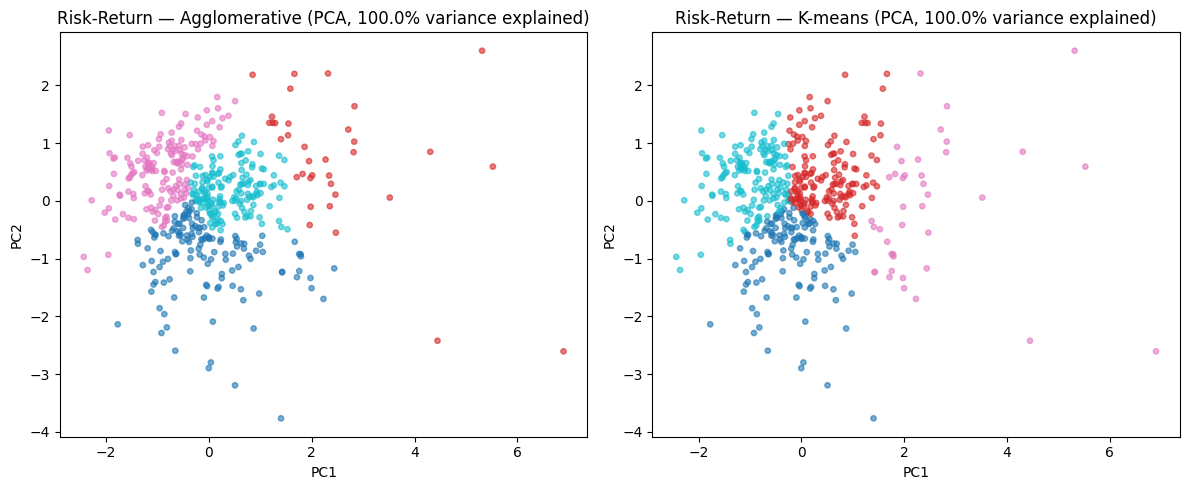

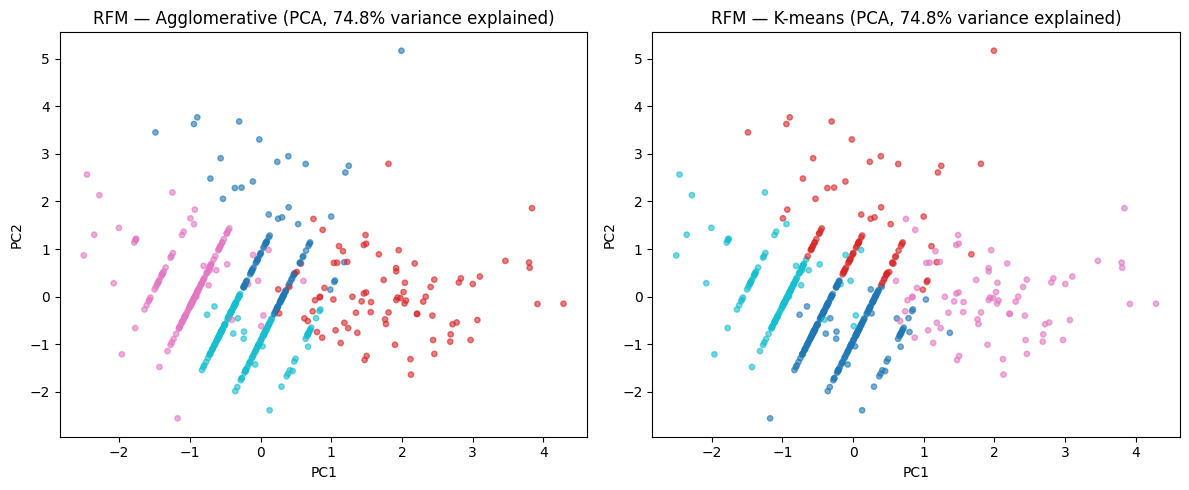

In [78]:
from sklearn.decomposition import PCA

def plot_clusters(X_scaled, labels_dict, title_prefix):
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)
    explained = pca.explained_variance_ratio_.sum()

    fig, axes = plt.subplots(1, len(labels_dict), figsize=(6*len(labels_dict), 5))
    if len(labels_dict) == 1:
        axes = [axes]
    for ax, (name, labels) in zip(axes, labels_dict.items()):
        scatter = ax.scatter(X_pca[:,0], X_pca[:,1], c=labels, cmap='tab10', alpha=0.6, s=15)
        ax.set_title(f"{title_prefix} — {name} (PCA, {explained:.1%} variance explained)")
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
    plt.tight_layout()
    plt.savefig(f"clusters_{title_prefix.replace(' ','_').replace('/','_')}.png", dpi=150)
    plt.show()

plot_clusters(risk_return_scaled.values, {"Agglomerative": agg_rr, "K-means": km_rr}, "Risk-Return")
plot_clusters(rfm_scaled.values, {"Agglomerative": agg_rfm, "K-means": km_rfm}, "RFM")

In [79]:
from sklearn.metrics import adjusted_rand_score

ari_rr = adjusted_rand_score(agg_rr, km_rr)
ari_rfm = adjusted_rand_score(agg_rfm, km_rfm)

print(f"ARI between Agglomerative and K-means — Risk/Return: {ari_rr:.3f}")
print(f"ARI between Agglomerative and K-means — RFM: {ari_rfm:.3f}")

ARI between Agglomerative and K-means — Risk/Return: 0.614
ARI between Agglomerative and K-means — RFM: 0.704


In [80]:
#2.5.1

In [81]:
corr_matrix = rfm_complete[["R", "F", "M_log"]].corr()
print(corr_matrix)

              R         F     M_log
R      1.000000 -0.192368  0.116814
F     -0.192368  1.000000  0.039829
M_log  0.116814  0.039829  1.000000


In [82]:
#2.5.2

In [83]:
rf_only_scaled = rfm_scaled[["R", "F"]].values

agg_rf_only = AgglomerativeClustering(n_clusters=4, linkage='ward').fit_predict(rf_only_scaled)

ari_rfm_vs_rf = adjusted_rand_score(agg_rfm, agg_rf_only)
print(f"ARI between full RFM (R,F,M) and RF-only Ward clustering: {ari_rfm_vs_rf:.3f}")

rfm_complete_labeled["rf_only_cluster"] = agg_rf_only
print("\nMean Monetary value by RF-only cluster:")
print(rfm_complete_labeled.groupby("rf_only_cluster")["M"].mean())

ARI between full RFM (R,F,M) and RF-only Ward clustering: 0.524

Mean Monetary value by RF-only cluster:
rf_only_cluster
0    4.928682e+10
1    3.433790e+10
2    3.775463e+10
3    2.786100e+10
Name: M, dtype: float64


In [84]:
risk_return_df_labeled.to_csv("risk_return_clusters.csv")
rfm_complete_labeled.to_csv("rfm_clusters.csv")
corr_matrix.to_csv("rfm_correlation_matrix.csv")


In [85]:
# Task 3

In [86]:
# sp500 table (from 1.1) already has GICS Sector info
sector_lookup = sp500[["Symbol", "GICS Sector"]].copy()
sector_lookup["Symbol"] = sector_lookup["Symbol"].str.replace('.', '-', regex=False)
sector_lookup = sector_lookup.set_index("Symbol")

# Merge sector into both labeled dataframes
risk_return_df_labeled = risk_return_df_labeled.join(sector_lookup, how="left")
rfm_complete_labeled = rfm_complete_labeled.join(sector_lookup, how="left")

print("Missing sector matches (risk/return):", risk_return_df_labeled["GICS Sector"].isna().sum())
print("Missing sector matches (RFM):", rfm_complete_labeled["GICS Sector"].isna().sum())

Missing sector matches (risk/return): 0
Missing sector matches (RFM): 0


In [87]:
sector_by_cluster_rr = pd.crosstab(risk_return_df_labeled["km_cluster"], risk_return_df_labeled["GICS Sector"])
print("=== Sector composition — Risk/Return clusters ===")
print(sector_by_cluster_rr)

sector_by_cluster_rfm = pd.crosstab(rfm_complete_labeled["km_cluster"], rfm_complete_labeled["GICS Sector"])
print("\n=== Sector composition — RFM clusters ===")
print(sector_by_cluster_rfm)

=== Sector composition — Risk/Return clusters ===
GICS Sector  Communication Services  Consumer Discretionary  Consumer Staples  \
km_cluster                                                                      
0                                 3                      17                 3   
1                                 7                      18                 2   
2                                 2                       7                 0   
3                                 9                       4                25   

GICS Sector  Energy  Financials  Health Care  Industrials  \
km_cluster                                                  
0                 0          19           22           19   
1                20          31            8           34   
2                 0           5            0            5   
3                 1          19           26           21   

GICS Sector  Information Technology  Materials  Real Estate  Utilities  
km_cluster             

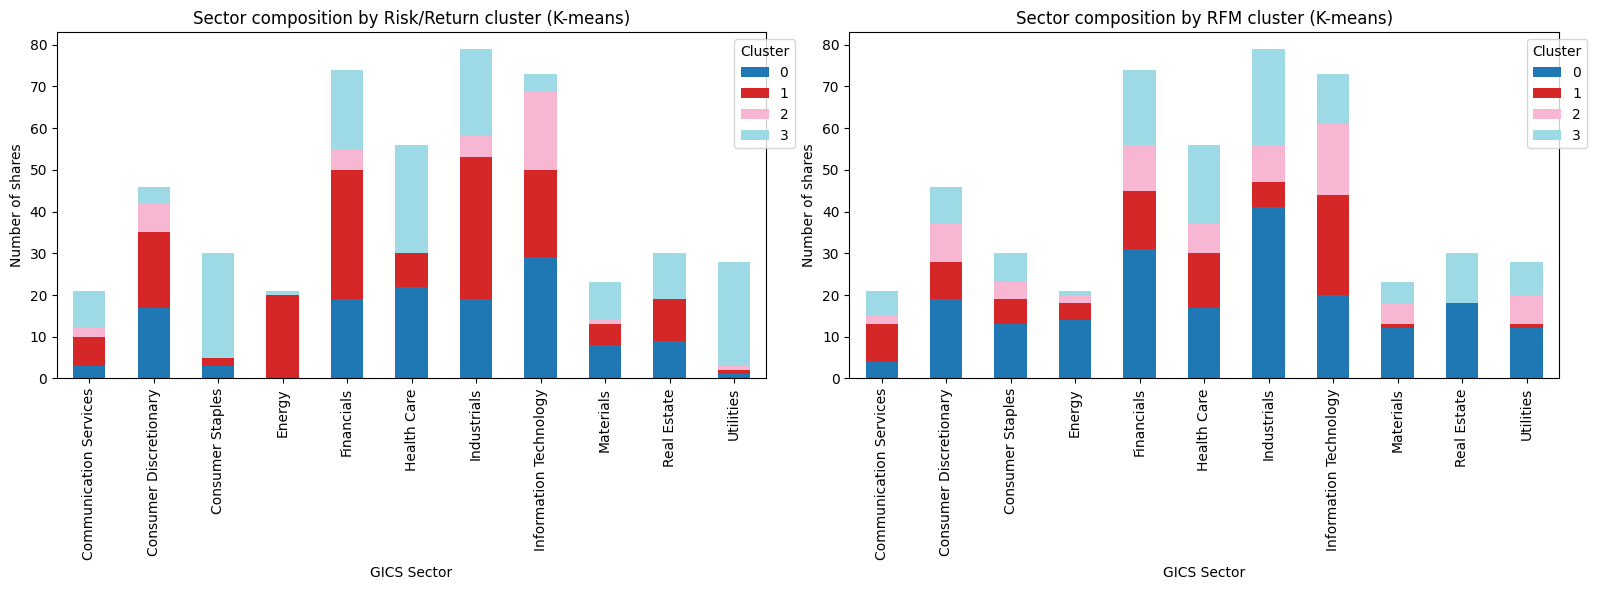

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sector_by_cluster_rr.T.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab20")
axes[0].set_title("Sector composition by Risk/Return cluster (K-means)")
axes[0].set_xlabel("GICS Sector")
axes[0].set_ylabel("Number of shares")
axes[0].legend(title="Cluster", bbox_to_anchor=(1.05, 1))

sector_by_cluster_rfm.T.plot(kind="bar", stacked=True, ax=axes[1], colormap="tab20")
axes[1].set_title("Sector composition by RFM cluster (K-means)")
axes[1].set_xlabel("GICS Sector")
axes[1].set_ylabel("Number of shares")
axes[1].legend(title="Cluster", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.savefig("sector_composition_by_cluster.png", dpi=150)
plt.show()

In [89]:
risk_return_df_labeled.to_csv("risk_return_clusters.csv")
rfm_complete_labeled.to_csv("rfm_clusters.csv")
corr_matrix.to_csv("rfm_correlation_matrix.csv")
sector_by_cluster_rr.to_csv("sector_composition_riskreturn.csv")
sector_by_cluster_rfm.to_csv("sector_composition_rfm.csv")

In [90]:
print('SYK' in data)
print('SYK' in valid_data)

True
True
